# Fase 6 — Implementação

O objetivo desta fase é incorporar o modelo à operação da empresa e encerrar o projeto de forma organizada. Entregáveis previstos no guia:

1. Plano de implementação (arquitetura)
2. Plano de monitoramento (obsolescência do modelo)
3. Relatório final
4. Revisão do projeto (lições aprendidas)

Como o projeto é acadêmico, não existe um sistema real onde implantar o modelo. Este notebook entrega o plano e uma demonstração executável do processo de pontuação.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

RAIZ = Path("..").resolve()
sys.path.append(str(RAIZ))
from src.preparacao import preparar_dados

sns.set_theme(style="whitegrid")
COR = "#2f6fab"

## 1. Plano de implementação

### 1.1 Arquitetura proposta

A pontuação é feita em lote, uma vez por mês, porque o cancelamento é uma decisão que amadurece ao longo de semanas e a equipe de retenção trabalha com listas de contato.

| Etapa | O que acontece | Responsável |
|---|---|---|
| 1. Extração | A base de clientes ativos é exportada do sistema de cadastro e cobrança, no mesmo formato da tabela original | Especialistas de banco de dados |
| 2. Preparação | A função `preparar_dados` (`src/preparacao.py`) aplica as regras da Fase 3 | Rotina automatizada |
| 3. Pontuação | O modelo salvo (`models/modelo_churn.joblib`) calcula a probabilidade de cancelamento de cada cliente | Rotina automatizada |
| 4. Decisão | Clientes com probabilidade igual ou maior que o limiar (`models/config_modelo.json`) entram na lista | Rotina automatizada |
| 5. Ação | A lista, ordenada por risco, vai para a equipe de retenção, que faz a oferta | Equipe de retenção |
| 6. Registro | O resultado de cada contato e os cancelamentos do mês seguinte são gravados | Equipe de retenção e banco de dados |

A etapa 6 é a que mais importa para o futuro do projeto: é ela que gera os dados que hoje não existem (custo real e sucesso real das ofertas).

### 1.2 Regras do modelo traduzidas para a equipe de TI

| Regra | Onde está |
|---|---|
| `TotalCharges` em branco vira permanência × mensalidade | `src/preparacao.py` |
| "No internet service" e "No phone service" viram "No" | `src/preparacao.py` |
| `SeniorCitizen` 0/1 vira No/Yes | `src/preparacao.py` |
| `FaixaTenure`: 0-12, 13-24, 25-48 e 49+ meses | `src/preparacao.py` |
| Atributos usados pelo modelo, padronização e one-hot encoding | Dentro do pipeline salvo em `models/modelo_churn.joblib` |
| Limiar de decisão e premissas de negócio | `models/config_modelo.json` |

O modelo deve ser carregado com a mesma versão do scikit-learn usada no treino, registrada no arquivo de configuração. Em outra versão, o caminho seguro é executar novamente o notebook da Fase 4.

### 1.3 Demonstração da pontuação

A função abaixo executa as etapas 2 a 4 a partir de uma tabela **bruta**, como chegaria do sistema da operadora.

In [2]:
def pontuar_clientes(df_bruto, modelo, config):
    """Recebe a tabela bruta de clientes e devolve a lista de retenção ordenada por risco."""
    preparado = preparar_dados(df_bruto)
    atributos = config["atributos_numericos"] + config["atributos_categoricos"]
    probabilidade = modelo.predict_proba(preparado[atributos])[:, 1]

    lista = preparado[["customerID", "tenure", "Contract", "InternetService", "MonthlyCharges"]].copy()
    lista["probabilidade_churn"] = probabilidade.round(4)
    lista["acao"] = np.select(
        [probabilidade >= 0.50, probabilidade >= config["limiar"]],
        ["Contatar - prioridade alta", "Contatar - prioridade normal"],
        default="Não contatar",
    )
    return lista.sort_values("probabilidade_churn", ascending=False).reset_index(drop=True)

modelo = joblib.load(RAIZ / "models" / "modelo_churn.joblib")
config = json.load(open(RAIZ / "models" / "config_modelo.json", encoding="utf-8"))
print("Modelo:", config["modelo"], "| limiar:", config["limiar"], "| scikit-learn:", config["versao_scikit_learn"])

Modelo: Regressão logística | limiar: 0.21 | scikit-learn: 1.9.1


Para simular a "base do mês", são usados os 1.409 clientes do conjunto de teste, lidos diretamente do arquivo bruto e sem a coluna `Churn`, como aconteceria em produção.

In [3]:
bruto = pd.read_csv(RAIZ / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
teste = pd.read_csv(RAIZ / "data" / "processed" / "teste.csv")

base_do_mes = bruto[bruto["customerID"].isin(teste["customerID"])].drop(columns="Churn")
lista = pontuar_clientes(base_do_mes, modelo, config)

print(lista["acao"].value_counts().to_string())
lista.head(10)

acao
Não contatar                    750
Contatar - prioridade normal    362
Contatar - prioridade alta      297


,customerID,tenure,Contract,InternetService,MonthlyCharges,probabilidade_churn,acao
0,5178-LMXOP,1,Month-to-month,Fiber optic,95.10,0.8848,Contatar - prioridade alta
1,0295-PPHDO,1,Month-to-month,Fiber optic,95.45,0.8646,Contatar - prioridade alta
2,8884-ADFVN,7,Month-to-month,Fiber optic,101.95,0.8598,Contatar - prioridade alta
3,6861-XWTWQ,7,Month-to-month,Fiber optic,99.25,0.8594,Contatar - prioridade alta
4,1400-MMYXY,3,Month-to-month,Fiber optic,105.90,0.8591,Contatar - prioridade alta
5,6023-YEBUP,3,Month-to-month,Fiber optic,100.95,0.8560,Contatar - prioridade alta
6,9057-SIHCH,3,Month-to-month,Fiber optic,96.60,0.8532,Contatar - prioridade alta
7,1069-XAIEM,1,Month-to-month,Fiber optic,85.05,0.8485,Contatar - prioridade alta
8,2545-EBUPK,2,Month-to-month,Fiber optic,84.05,0.8436,Contatar - prioridade alta
9,6630-UJZMY,4,Month-to-month,Fiber optic,83.25,0.8372,Contatar - prioridade alta


In [4]:
# Conferência: a pontuação a partir do dado bruto reproduz a da Fase 5?
atributos = config["atributos_numericos"] + config["atributos_categoricos"]
prob_fase5 = pd.Series(modelo.predict_proba(teste[atributos])[:, 1], index=teste["customerID"])
prob_producao = lista.set_index("customerID")["probabilidade_churn"]
diferenca = (prob_fase5 - prob_producao.reindex(prob_fase5.index)).abs().max()
print(f"Maior diferença entre as duas pontuações: {diferenca:.6f}")
assert diferenca < 1e-4

destino = RAIZ / "reports" / "lista_retencao_exemplo.csv"
lista[lista["acao"] != "Não contatar"].to_csv(destino, index=False)
print("Lista salva em:", destino.relative_to(RAIZ))

Maior diferença entre as duas pontuações: 0.000050
Lista salva em: reports/lista_retencao_exemplo.csv


A pontuação feita a partir do dado bruto coincide com a da Fase 5 (a diferença máxima vem apenas do arredondamento em quatro casas decimais), o que confirma que a preparação e o modelo funcionam de ponta a ponta fora dos notebooks de desenvolvimento. A lista de exemplo tem 659 clientes para contato, o mesmo número avaliado na Fase 5.

### 1.4 Piloto controlado

A Fase 5 concluiu que o retorno financeiro depende de premissas não validadas. Por isso a implementação começa com um piloto:

| Item | Proposta |
|---|---|
| Duração | 3 meses |
| Grupo de tratamento | Uma parte dos clientes indicados pelo modelo, sorteada, recebe a oferta |
| Grupo de controle | O restante dos clientes indicados não recebe a oferta |
| O que se mede | Taxa de cancelamento nos dois grupos, custo real por contato e receita preservada |
| Resultado esperado | Valores reais para substituir as premissas de `src/negocio.py` e recalcular o limiar |

A comparação entre os dois grupos é a única forma de medir o efeito da oferta em si, separado da capacidade do modelo de prever quem sairia.

## 2. Plano de monitoramento

Um modelo de churn perde validade quando mudam os preços, os produtos, a concorrência ou o perfil dos clientes. O plano abaixo define o que acompanhar e quando agir.

| Indicador | Frequência | Sinal de alerta | Ação |
|---|---|---|---|
| Qualidade da entrada: nulos, categorias novas, valores fora de faixa | A cada pontuação | Qualquer categoria desconhecida ou valor ausente inesperado | Corrigir a extração antes de pontuar |
| Estabilidade da distribuição das probabilidades (PSI) | Mensal | PSI acima de 0,10 pede atenção; acima de 0,25 pede investigação | Verificar mudanças na base ou no produto |
| Fração da base indicada para contato | Mensal | Variação maior que 10 pontos percentuais em relação aos 47% atuais | Revisar o limiar |
| ROC-AUC e recall com os cancelamentos reais | Mensal, com um mês de defasagem | ROC-AUC abaixo de 0,80 ou recall abaixo de 0,70 (critérios da Fase 1) | Treinar novamente |
| Retorno real da campanha | Trimestral | Retorno líquido negativo | Revisar a oferta e o limiar |
| Peso dos atributos sensíveis | A cada novo treino | Aumento relevante dos coeficientes de gênero ou idade | Revisar os atributos |

**Novo treino:** a cada 6 meses, ou antes, se algum alerta de desempenho disparar. Mudanças de tabela de preços ou lançamento de novos planos também justificam um novo treino.

Os limites de 0,10 e 0,25 para o PSI são uma convenção de mercado, e não um resultado deste projeto.

### Demonstração do PSI

O PSI (*Population Stability Index*) compara a distribuição das probabilidades em uma base nova com a distribuição de referência. Aqui a referência é o treino e a "base nova" é o teste. Como os dois vêm do mesmo sorteio, o esperado é um valor próximo de zero.

PSI entre treino e teste: 0.0069
Fração indicada para contato: treino 46.8% | teste 46.8%


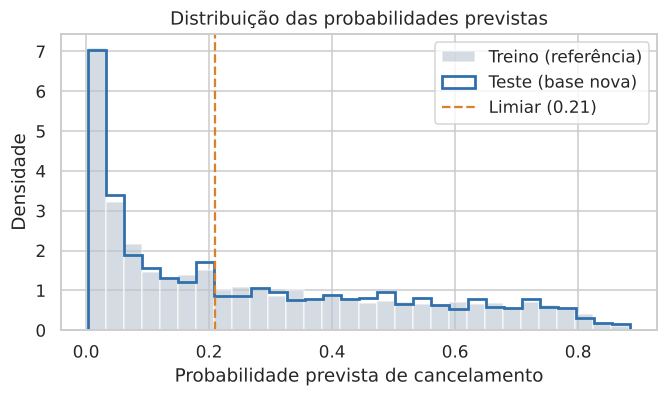

In [5]:
def psi(referencia, atual, faixas=10):
    """Population Stability Index entre duas distribuições de probabilidades."""
    cortes = np.quantile(referencia, np.linspace(0, 1, faixas + 1))
    cortes[0], cortes[-1] = -np.inf, np.inf
    p_ref = np.histogram(referencia, bins=cortes)[0] / len(referencia)
    p_atual = np.histogram(atual, bins=cortes)[0] / len(atual)
    p_ref, p_atual = np.clip(p_ref, 1e-6, None), np.clip(p_atual, 1e-6, None)
    return float(np.sum((p_atual - p_ref) * np.log(p_atual / p_ref)))

treino = pd.read_csv(RAIZ / "data" / "processed" / "treino.csv")
prob_treino = modelo.predict_proba(treino[atributos])[:, 1]
prob_teste = modelo.predict_proba(teste[atributos])[:, 1]

print(f"PSI entre treino e teste: {psi(prob_treino, prob_teste):.4f}")
print(f"Fração indicada para contato: treino {np.mean(prob_treino >= config['limiar']):.1%} | teste {np.mean(prob_teste >= config['limiar']):.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(prob_treino, bins=30, density=True, alpha=0.6, color="#b8c4d0", label="Treino (referência)")
ax.hist(prob_teste, bins=30, density=True, histtype="step", linewidth=1.8, color=COR, label="Teste (base nova)")
ax.axvline(config["limiar"], color="#d9822b", linestyle="--", label=f"Limiar ({config['limiar']})")
ax.set_xlabel("Probabilidade prevista de cancelamento")
ax.set_ylabel("Densidade")
ax.set_title("Distribuição das probabilidades previstas")
ax.legend()
plt.show()

O PSI de 0,007 confirma que as duas distribuições são praticamente iguais, e a fração de clientes indicada para contato é a mesma nos dois conjuntos (46,8%). Em produção, o mesmo cálculo seria feito todo mês, comparando a base pontuada com a referência do treino.

## 3. Relatório final

### Resumo executivo

**Problema.** Na base analisada, 26,5% dos clientes cancelaram, e eles respondiam por 30,5% da receita mensal. A operadora não tinha como saber com antecedência quem estava em risco.

**Solução.** Um modelo de regressão logística que estima a probabilidade de cancelamento de cada cliente a partir de 19 atributos de perfil, serviços, contrato e cobrança. Clientes com probabilidade de 0,21 ou mais entram na lista de retenção.

**Resultados no conjunto de teste (1.409 clientes que o modelo não viu):**

| Critério da Fase 1 | Meta | Resultado |
|---|---|---|
| CN1: cancelamentos alcançados pela campanha | ≥ 70% | 84,8% (317 de 374) |
| CN2: retorno líquido simulado | Positivo e maior do que contatar todos | $ 52,4 mil contra $ 27,5 mil |
| CN3: fatores de risco com sentido comercial | Sim | Tempo de casa, tipo de internet e tipo de contrato |
| CT1: ROC-AUC | ≥ 0,80 | 0,843 |
| CT2: recall no limiar | ≥ 0,70 | 0,848 |
| CT3: teste próximo da validação | Diferença até 0,02 | 0,843 contra 0,847 |

**O que os dados mostram sobre quem cancela.** Clientes com contrato mensal, com menos de um ano de casa, com internet por fibra e sem serviços de segurança ou suporte técnico.

**Ressalva principal.** O retorno em dólares é uma simulação baseada em três premissas (custo de $ 50 por contato, 30% de sucesso da oferta e 12 mensalidades preservadas). Em cenários de oferta cara ou pouco eficaz, a campanha daria prejuízo.

**Recomendação.** Implementar como piloto controlado de 3 meses, com grupo de controle, para medir o custo e o efeito reais da oferta antes de ampliar a campanha.

## 4. Revisão do projeto

### 4.1 Iterações do ciclo CRISP-DM

O guia destaca que recuar no ciclo não é falhar. Estes foram os retornos que aconteceram no projeto:

| De | Para | Motivo | O que mudou |
|---|---|---|---|
| Entendimento dos Dados | Entendimento do Negócio | A base não tem custos nem resultados de ofertas de retenção | O critério financeiro (CN2) passou a ser avaliado por simulação, com premissas declaradas e análise de sensibilidade |
| Preparação | Entendimento dos Dados | O atributo `VariacaoCobranca` foi criado para testar a hipótese de aumento de preço | A hipótese não se confirmou e o atributo foi descartado |
| Modelagem | Preparação | Os coeficientes da regressão logística tinham sinais contrários ao observado nos dados | `MonthlyCharges` e `NumServicosAdicionais`, redundantes com as colunas de serviços, saíram do modelo |
| Modelagem | Entendimento do Negócio | No limiar padrão de 0,50 o recall ficava em 0,54, abaixo da meta | O limiar passou a ser definido pelo retorno simulado da campanha (0,21) |
| Avaliação | Entendimento do Negócio | O retorno depende de premissas não validadas | A implementação foi redefinida como piloto controlado |

### 4.2 Lições aprendidas

1. **Definir os critérios de sucesso antes de modelar evitou escolher a métrica depois de ver o resultado.** A acurácia do modelo final (71,7%) é menor que a de um classificador ingênuo (73,5%), e mesmo assim ele atende ao objetivo de negócio.
2. **A decisão que mais mexeu no resultado foi o limiar, e não o algoritmo.** Quatro algoritmos diferentes chegaram praticamente à mesma ROC-AUC, enquanto a mudança do limiar levou o recall de 0,54 para 0,85.
3. **Um bom desempenho pode esconder um modelo incoerente.** Com atributos redundantes, a ROC-AUC era a mesma, mas os coeficientes diziam o contrário dos dados. Só a inspeção do modelo revelou o problema.
4. **A redundância poderia ter sido detectada mais cedo.** Uma verificação de relação entre atributos na Fase 2 teria evitado uma iteração.
5. **Nem todo atributo derivado ajuda.** Dos três atributos construídos, um foi descartado por não ter relação com o alvo e outro saiu do modelo por ser redundante.
6. **Concentrar as regras de preparação em uma função facilitou a implementação.** A mesma função atende ao treino e à pontuação, e a conferência da seção 1.3 mostrou resultados idênticos.
7. **O limite do projeto está nos dados, e não na técnica.** Sem datas, sem histórico de atendimento e sem resultados de campanhas, mais modelagem não melhoraria as respostas.

### 4.3 Próximos passos

- Executar o piloto controlado e substituir as premissas por valores medidos.
- Recalcular o limiar com os valores reais.
- Incluir novas fontes de dados (atendimento, reclamações, uso dos serviços) em um novo ciclo, a partir da Fase 2.
- Com os dados do piloto, estudar um modelo que estime o efeito da oferta em cada cliente, e não apenas o risco de saída.